# ML Assignment 2 - Credit Risk Classification

**Course:** Machine Learning (S1-26_AIMLZG565)
**Dataset:** Statlog (German Credit Data), UCI Machine Learning Repository

In this notebook I train five classifiers on the German Credit dataset, compare them on six metrics and save the
trained pipelines in `model/`. The Streamlit app (`app.py`) only loads these saved files, it never retrains.

Steps:
1. Load the raw UCI file and decode the `A11`, `A34`... codes into readable values
2. Quick data check (missing values, duplicates, class balance)
3. Train/test split
4. Preprocessing (scaling + one-hot encoding) inside a Pipeline
5. Five models with a small grid search on the training data
6. Evaluation on the test set (Accuracy, AUC, Precision, Recall, F1, MCC)
7. Save models + `test_data.csv`

In [1]:
import os
import warnings
# sklearn 1.9 prints a FutureWarning for SVC(probability=True) in every CV fold. It still works fine,
# so I hide that warning (env variable as well, so the parallel grid-search workers are quiet too)
os.environ["PYTHONWARNINGS"] = "ignore::FutureWarning"
warnings.filterwarnings("ignore", category=FutureWarning)

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix, classification_report)

RANDOM_STATE = 5167   # last digits of my BITS ID - used for the split, CV folds and the models

## 1. Load the raw data

`german.data` is space separated and has no header row. 13 of the 20 attributes are stored as codes
(`A11`, `A12`, ...). I name the columns and map every code to the meaning given in `german.doc`, so the
test CSV and the app are readable.

In [2]:
columns = ["checking_account", "duration_months", "credit_history", "purpose", "credit_amount",
           "savings_account", "employment_since", "installment_rate", "personal_status_sex",
           "other_debtors", "residence_since", "property", "age", "other_installment_plans",
           "housing", "existing_credits", "job", "num_dependents", "telephone", "foreign_worker",
           "credit_risk"]

raw = pd.read_csv("data/german.data", sep=" ", header=None, names=columns)
print("shape:", raw.shape)
raw.head(3)

shape: (1000, 21)


,checking_account,duration_months,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,credit_risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1


In [3]:
code_map = {
    "checking_account": {"A11": "< 0 DM", "A12": "0-200 DM", "A13": ">= 200 DM", "A14": "no account"},
    "credit_history": {"A30": "no credits / all paid", "A31": "all paid at this bank",
                       "A32": "existing paid till now", "A33": "delay in past", "A34": "critical account"},
    "purpose": {"A40": "car (new)", "A41": "car (used)", "A42": "furniture/equipment", "A43": "radio/tv",
                "A44": "domestic appliances", "A45": "repairs", "A46": "education", "A47": "vacation",
                "A48": "retraining", "A49": "business", "A410": "others"},
    "savings_account": {"A61": "< 100 DM", "A62": "100-500 DM", "A63": "500-1000 DM",
                        "A64": ">= 1000 DM", "A65": "unknown / none"},
    "employment_since": {"A71": "unemployed", "A72": "< 1 year", "A73": "1-4 years",
                         "A74": "4-7 years", "A75": ">= 7 years"},
    "personal_status_sex": {"A91": "male divorced/separated", "A92": "female div/sep/married",
                            "A93": "male single", "A94": "male married/widowed", "A95": "female single"},
    "other_debtors": {"A101": "none", "A102": "co-applicant", "A103": "guarantor"},
    "property": {"A121": "real estate", "A122": "savings agreement/life insurance",
                 "A123": "car or other", "A124": "unknown / no property"},
    "other_installment_plans": {"A141": "bank", "A142": "stores", "A143": "none"},
    "housing": {"A151": "rent", "A152": "own", "A153": "for free"},
    "job": {"A171": "unemployed/unskilled non-resident", "A172": "unskilled resident",
            "A173": "skilled employee", "A174": "management/highly qualified"},
    "telephone": {"A191": "none", "A192": "yes"},
    "foreign_worker": {"A201": "yes", "A202": "no"},
}

df = raw.copy()
for col, mapping in code_map.items():
    df[col] = df[col].map(mapping)

# in the original file 1 = good, 2 = bad
df["credit_risk"] = df["credit_risk"].map({1: "good", 2: "bad"})

# if I made a typo in the dict, map() would give NaN - so this must print 0
print("NaN after decoding:", df.isnull().sum().sum())
df.to_csv("data/german_credit_clean.csv", index=False)
df.head(3)

NaN after decoding: 0


,checking_account,duration_months,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,credit_risk
0,< 0 DM,6,critical account,radio/tv,1169,unknown / none,>= 7 years,4,male single,none,...,real estate,67,none,own,2,skilled employee,1,yes,yes,good
1,0-200 DM,48,existing paid till now,radio/tv,5951,< 100 DM,1-4 years,2,female div/sep/married,none,...,real estate,22,none,own,1,skilled employee,1,none,yes,bad
2,no account,12,critical account,education,2096,< 100 DM,4-7 years,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good


## 2. Quick look at the data

In [4]:
print("rows, columns:", df.shape)
print("missing values:", df.isnull().sum().sum())
print("duplicate rows:", df.duplicated().sum())
print()
print(df.dtypes.value_counts())
print()
counts = df["credit_risk"].value_counts()
print(pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(1)}))

rows, columns: (1000, 21)
missing values: 0
duplicate rows: 0

str      14
int64     7
Name: count, dtype: int64

             count  percent
credit_risk                
good           700     70.0
bad            300     30.0


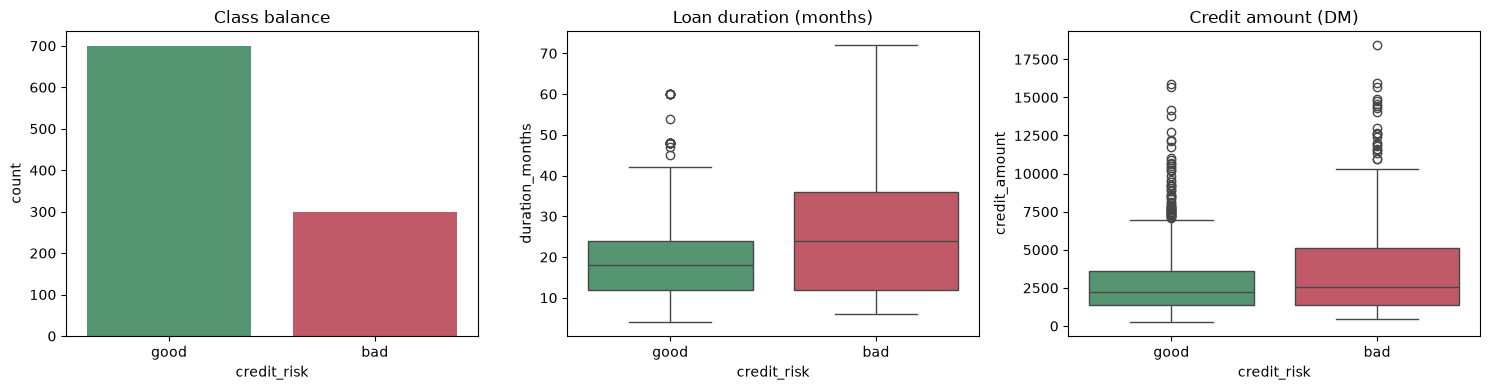

             duration_months  credit_amount   age
credit_risk                                      
bad                     24.0         2574.5  31.0
good                    18.0         2244.0  34.0

bad rate by checking account status:
checking_account
0-200 DM      39.0
< 0 DM        49.3
>= 200 DM     22.2
no account    11.7
Name: bad, dtype: float64


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df, x="credit_risk", hue="credit_risk", ax=axes[0], legend=False,
              palette={"good": "#4C9F70", "bad": "#D1495B"})
axes[0].set_title("Class balance")
sns.boxplot(data=df, x="credit_risk", y="duration_months", hue="credit_risk", ax=axes[1], legend=False,
            palette={"good": "#4C9F70", "bad": "#D1495B"})
axes[1].set_title("Loan duration (months)")
sns.boxplot(data=df, x="credit_risk", y="credit_amount", hue="credit_risk", ax=axes[2], legend=False,
            palette={"good": "#4C9F70", "bad": "#D1495B"})
axes[2].set_title("Credit amount (DM)")
plt.tight_layout()
plt.show()

print(df.groupby("credit_risk")[["duration_months", "credit_amount", "age"]].median())
print()
print("bad rate by checking account status:")
print((pd.crosstab(df["checking_account"], df["credit_risk"], normalize="index")["bad"] * 100).round(1))

**What the data shows**
- 700 good and 300 bad, so the classes are imbalanced (70/30). A "model" that says *good* for everyone already gets
  70% accuracy, so accuracy alone is not a fair way to compare the models here. I will rely more on AUC, F1 and MCC.
- No missing values and no duplicate rows, so nothing had to be dropped or imputed.
- Bad loans run longer (median 24 vs 18 months) and are a bit larger.
- Checking account status looks like a strong signal: about 49% of applicants with a negative balance are bad,
  against about 12% of applicants with no checking account at this bank.

## 3. Features, target and train/test split

I take **bad** credit risk as the positive class (label 1). For a bank the costly mistake is giving a loan
to someone who will not pay it back, so precision, recall and F1 below are all measured for the *bad* class.

80/20 split, stratified so both parts keep the same 70/30 ratio.

In [6]:
X = df.drop(columns=["credit_risk"])
y = (df["credit_risk"] == "bad").astype(int)      # 1 = bad, 0 = good

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]
print(len(num_cols), "numeric:", num_cols)
print(len(cat_cols), "categorical:", cat_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("\ntrain:", X_train.shape, "  test:", X_test.shape)
print("share of bad -> full: %.3f  train: %.3f  test: %.3f" % (y.mean(), y_train.mean(), y_test.mean()))

7 numeric: ['duration_months', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'num_dependents']
13 categorical: ['checking_account', 'credit_history', 'purpose', 'savings_account', 'employment_since', 'personal_status_sex', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']

train: (800, 20)   test: (200, 20)
share of bad -> full: 0.300  train: 0.300  test: 0.300


## 4. Preprocessing

- numeric columns -> `StandardScaler` (KNN, SVM and Logistic Regression depend on the scale of the inputs)
- categorical columns -> `OneHotEncoder(handle_unknown="ignore")`

The preprocessor goes **inside** a `Pipeline` together with each model. Two reasons:
1. the scaler and encoder are fitted only on the training folds, so no information leaks from the test data
2. the saved `.joblib` file holds preprocessing + model together, so the app can be given the raw CSV columns

In [7]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])

n_after = make_preprocessor().fit(X_train).transform(X_train.head(1)).shape[1]
print("features after one-hot encoding:", n_after)

features after one-hot encoding: 61


## 5. Models and hyper-parameter search

All five models use the same split and the same preprocessor. For each one I run a small `GridSearchCV`
(5-fold stratified CV on the **training set only**). The score used to pick the parameters is F1 of the bad class,
because with a 70/30 split plain accuracy would favour models that just say "good" most of the time.

`class_weight="balanced"` is one of the options for Logistic Regression, Decision Tree and SVM
(KNN and Gaussian NB do not have this parameter). SVM needs `probability=True` so that I can compute AUC.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

model_setups = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000),
        {"clf__C": [0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"clf__max_depth": [3, 4, 5, 6, 8, None], "clf__min_samples_leaf": [1, 5, 10, 20],
         "clf__criterion": ["gini", "entropy"], "clf__class_weight": [None, "balanced"]}),
    "KNN": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [3, 5, 7, 9, 11, 15, 21], "clf__weights": ["uniform", "distance"]}),
    "Naive Bayes": (
        GaussianNB(),
        {"clf__var_smoothing": [1e-9, 1e-6, 1e-3, 1e-2, 1e-1]}),
    "Support Vector Machine": (
        SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
        {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01, 0.1],
         "clf__class_weight": [None, "balanced"]}),
}

best_models = {}
for name, (clf, grid) in model_setups.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", clf)])
    search = GridSearchCV(pipe, grid, scoring="f1", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    params = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
    print(f"{name:24s} CV F1 = {search.best_score_:.4f}   {params}")

Logistic Regression      CV F1 = 0.6163   {'C': 10, 'class_weight': 'balanced'}


Decision Tree            CV F1 = 0.5787   {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 20}


KNN                      CV F1 = 0.4498   {'n_neighbors': 3, 'weights': 'uniform'}


Naive Bayes              CV F1 = 0.5826   {'var_smoothing': 0.001}


Support Vector Machine   CV F1 = 0.6107   {'C': 1, 'class_weight': 'balanced', 'gamma': 0.01}


## 6. Evaluation on the test set

AUC is calculated from the predicted probability of the bad class (`predict_proba[:, 1]`), the other five
metrics from the predicted labels.

In [9]:
def evaluate(model, X_part, y_part):
    y_pred = model.predict(X_part)
    y_prob = model.predict_proba(X_part)[:, 1]
    return {
        "Accuracy": accuracy_score(y_part, y_pred),
        "AUC": roc_auc_score(y_part, y_prob),
        "Precision": precision_score(y_part, y_pred, zero_division=0),
        "Recall": recall_score(y_part, y_pred, zero_division=0),
        "F1": f1_score(y_part, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_part, y_pred),
    }

results = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in best_models.items()}).T
results.index.name = "ML Model Name"
results.round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.690,0.7725,0.4884,0.7000,0.5753,0.3570
Decision Tree,0.615,0.6783,0.4261,0.8167,0.5600,0.3200
KNN,0.725,0.7125,0.5714,0.3333,0.4211,0.2728
Naive Bayes,0.675,0.7364,0.4737,0.7500,0.5806,0.3605
Support Vector Machine,0.685,0.7890,0.4839,0.7500,0.5882,0.3741


In [10]:
# reference point: a "model" that calls every applicant good
always_good = np.zeros_like(y_test)
print("always 'good' -> accuracy = %.3f, MCC = %.3f"
      % (accuracy_score(y_test, always_good), matthews_corrcoef(y_test, always_good)))

always 'good' -> accuracy = 0.700, MCC = 0.000


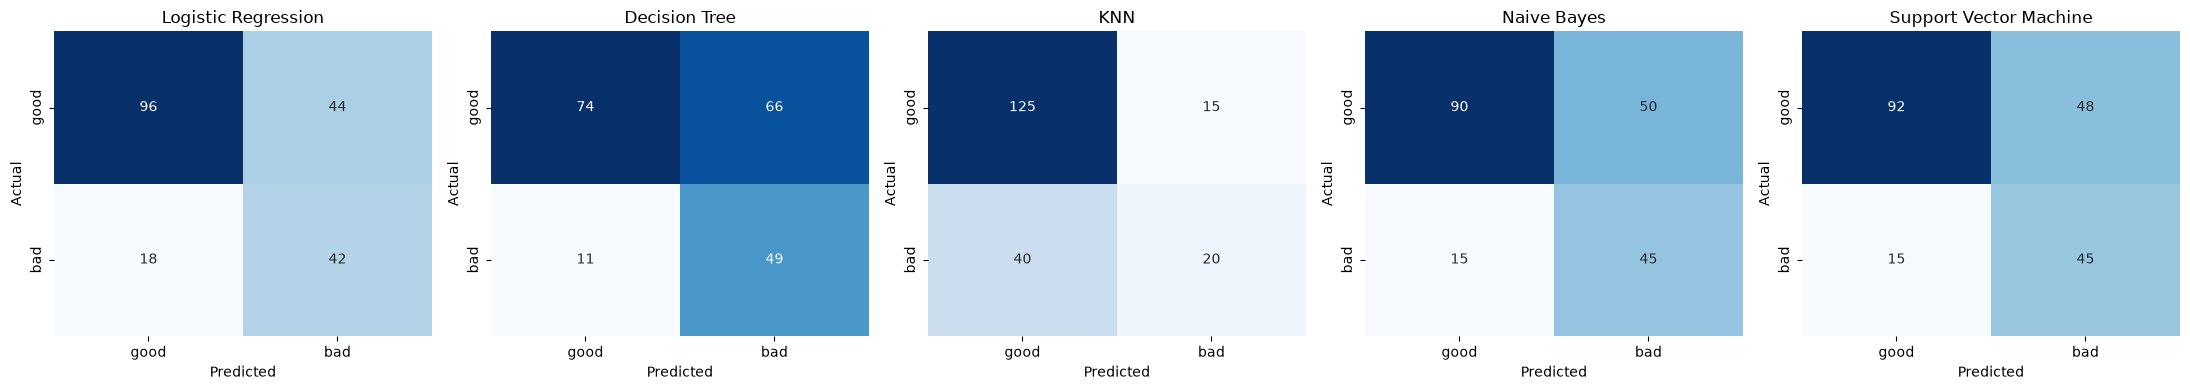

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, model) in zip(axes, best_models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cbar=False, cmap="Blues", ax=ax,
                xticklabels=["good", "bad"], yticklabels=["good", "bad"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [12]:
for name, model in best_models.items():
    print("=" * 20, name, "=" * 20)
    print(classification_report(y_test, model.predict(X_test), target_names=["good", "bad"], digits=4))

==================== Logistic Regression ====================
              precision    recall  f1-score   support

        good     0.8421    0.6857    0.7559       140
         bad     0.4884    0.7000    0.5753        60

    accuracy                         0.6900       200
   macro avg     0.6652    0.6929    0.6656       200
weighted avg     0.7360    0.6900    0.7017       200

==================== Decision Tree ====================
              precision    recall  f1-score   support

        good     0.8706    0.5286    0.6578       140
         bad     0.4261    0.8167    0.5600        60

    accuracy                         0.6150       200
   macro avg     0.6483    0.6726    0.6089       200
weighted avg     0.7372    0.6150    0.6284       200

==================== KNN ====================
              precision    recall  f1-score   support

        good     0.7576    0.8929    0.8197       140
         bad     0.5714    0.3333    0.4211        60

    accuracy      

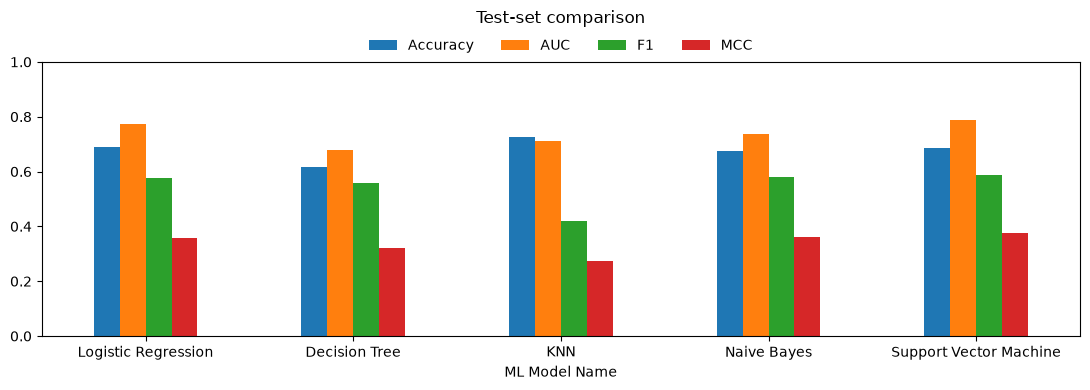

In [13]:
ax = results[["Accuracy", "AUC", "F1", "MCC"]].plot(kind="bar", figsize=(11, 4), rot=0)
ax.set_ylim(0, 1)
ax.set_title("Test-set comparison", pad=28)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.13), ncol=4, frameon=False)
plt.tight_layout()
plt.show()

### Observations

| Model | What I see |
|---|---|
| Logistic Regression | AUC 0.77, MCC 0.36. Grid search picked `class_weight="balanced"`, so it catches 70% of the bad applicants (recall 0.70) at precision 0.49. A simple linear model, and still close to the best, so most of the signal is roughly linear after one-hot encoding. |
| Decision Tree | Highest recall (0.82) but the lowest accuracy (0.615) and AUC (0.68). The tree is shallow (`max_depth=4`, balanced weights), so it labels many good applicants as bad (precision 0.43). Easy to explain, but its probability scores are coarse because there are only a few leaves, which hurts AUC. |
| KNN | Highest accuracy (0.725), but that number is misleading: recall is only 0.33, so it misses two out of three bad applicants. KNN has no `class_weight` option, so it follows the majority class. It has the lowest F1 (0.42) and MCC (0.27), only a little better than always saying "good" (accuracy 0.70, MCC 0). |
| Naive Bayes | Better than I expected: recall 0.75, F1 0.58 and MCC 0.36, about the same as Logistic Regression. The independence assumption does not really hold (for example, duration and credit amount have a correlation of about 0.62), but it still ranks applicants reasonably well (AUC 0.74). |
| Support Vector Machine | Best AUC (0.789), F1 (0.588) and MCC (0.374), with recall 0.75. The RBF kernel with balanced class weights separates the two classes a little better than the linear model. Slowest to train and the hardest to interpret. |

**Winner for this dataset: SVM (RBF kernel).** It is the best on AUC, F1 and MCC, which are the metrics that matter
when the bad class is the minority. Naive Bayes and Logistic Regression are close behind, and Logistic Regression
would be my pick if the bank needed to explain each decision. The differences between the top three are small
on a 200-row test set, so I would not call SVM clearly better than LR or NB.

## 7. Save the models and the test data

Each saved pipeline = preprocessor + tuned classifier. `test_data.csv` is the 20% hold-out part with all
20 input columns plus the `credit_risk` target, which is the file to upload in the app.

In [14]:
file_names = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib",
}

os.makedirs("model", exist_ok=True)
for name, model in best_models.items():
    joblib.dump(model, os.path.join("model", file_names[name]))

results.round(4).to_csv("model/model_comparison.csv")

test_data = X_test.copy()
test_data["credit_risk"] = y_test.map({1: "bad", 0: "good"})
test_data.to_csv("test_data.csv", index=False)

print(os.listdir("model"))
print("test_data.csv:", test_data.shape)

['model_comparison.csv', 'decision_tree.joblib', 'svm.joblib', 'knn.joblib', 'logistic_regression.joblib', 'naive_bayes.joblib']
test_data.csv: (200, 21)


In [15]:
# sanity check: load the files back (like the app does) and make sure the metrics are identical
check_X = pd.read_csv("test_data.csv")
check_y = (check_X.pop("credit_risk") == "bad").astype(int)
for name, fname in file_names.items():
    loaded = joblib.load(os.path.join("model", fname))
    m = evaluate(loaded, check_X, check_y)
    assert all(np.isclose(m[k], results.loc[name, k]) for k in m), name
print("all 5 saved models reload and reproduce the test metrics")

all 5 saved models reload and reproduce the test metrics
